# Chapter 4: Regression and Tree-Based Models

> **Course**: Graduate course on Machine Learning / Big Data Analytics (lecture notebook)  
> **Theme**: An end-to-end regression workflow on California housing data, followed by a comparison of tree-based models on a classification task (MNIST handwritten digits)

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/hanchen92/THU-STAT-BigData-115-1-6199/blob/main/05_tree_based_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/hanchen92/THU-STAT-BigData-115-1-6199/main/05_tree_based_model.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

## Learning Objectives

After completing this chapter, you should be able to:

1. Explain why a **test set** must be held out first, and how **stratified sampling** makes it representative.
2. Build a reusable, **leakage-free** preprocessing workflow with `Pipeline` and `ColumnTransformer` (imputation, transformation, scaling, categorical encoding).
3. Train and compare three tree-based models: **decision tree, random forest, gradient boosting**.
4. Understand **overfitting**: why training error does not reflect real performance, and how **cross-validation** gives a more reliable estimate.
5. Control decision-tree complexity with **cost-complexity pruning**.
6. Contrast evaluation in **regression** (continuous target, metric: RMSE) and **classification** (categorical target, metric: accuracy).

## Chapter Outline

| Section | Content | Task type |
|---|---|---|
| 1 | Environment setup | – |
| 2 | Data collection (California housing) | – |
| 3 | Creating a test set (stratified sampling) | – |
| 4 | Data exploration | – |
| 5 | Feature engineering | – |
| 6 | Preprocessing (categorical encoding, feature scaling, `ColumnTransformer`) | – |
| 7 | Model selection and training: decision tree / random forest / gradient boosting | **Regression** |
| 8 | MNIST digits: decision tree / random forest / gradient boosting | **Classification** |
| 9 | Summary and discussion questions | – |

## Requirements

`numpy`, `pandas`, `matplotlib`, `scikit-learn` (**version ≥ 1.2 recommended**, because the code uses the `OneHotEncoder(sparse_output=...)` parameter).

---
# 1. Environment Setup

We import only the basic packages here. Other scikit-learn submodules are imported where they are first used, so you can see which tools each step relies on.

In [1]:
import sklearn                    # scikit-learn: the machine learning library used in this course
import numpy as np                # NumPy: numerical computing and arrays
import matplotlib.pyplot as plt   # Matplotlib: plotting

---
# 2. Data Collection

*Welcome to Machine Learning Housing Corp.! Your task is to predict median house values in Californian districts, given a number of features from these districts.*

This is a classic **regression** problem in **supervised learning**:

- **Target (label)**: `median_house_value` (median house value of the district, in US dollars), a continuous variable.
- **Features**: location, housing age, number of rooms, population, median income, proximity to the ocean, etc.
- **Unit of observation**: each row is a *district (block group)*, not an individual house.

## 2.1 Download the Data

The function `load_housing_data()` does three things:

1. Checks whether `datasets/housing.tgz` already exists locally;
2. If not, downloads and extracts it;
3. Reads the CSV into a pandas `DataFrame`.

Main columns of the dataset:

| Column | Description |
|---|---|
| `longitude`, `latitude` | Geographic coordinates |
| `housing_median_age` | Median age of houses in the district |
| `total_rooms`, `total_bedrooms` | Total rooms / bedrooms in the district (**note: district-wide totals**) |
| `population`, `households` | Population and number of households in the district |
| `median_income` | Median household income (roughly in tens of thousands of USD) |
| `ocean_proximity` | Distance-to-ocean category (**categorical variable**) |
| `median_house_value` | **Target**: median house value (USD) |

In [2]:
from pathlib import Path          # Object-oriented file paths (works across operating systems)
import pandas as pd               # pandas: tabular data (DataFrame)
import tarfile                    # Extract .tgz archives
import urllib.request             # Download files from the web

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    # Download only if the archive is not already on disk (avoids re-downloading on every run)
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)    # Create folder (no error if it exists)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)           # Download the archive
        with tarfile.open(tarball_path) as housing_tarball:
            # Extract into datasets/ (on Python 3.12+, adding filter="data" is recommended for safety)
            housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))   # Read the CSV into a DataFrame

housing = load_housing_data()   # housing now holds the FULL data; not yet split into train/test

## 2.2 Helper Function: Saving Figures

The function below saves a Matplotlib figure as a high-resolution PNG (300 dpi by default) for reports or papers.  
**It is not required for modeling** (the original author labels it `extra code`); it is used later in the MNIST section.

In [3]:
# extra code – code to save the figures as high-res PNGs for the book
IMAGES_PATH = Path() / "images" / "end_to_end_project"   # Output folder: ./images/end_to_end_project/
IMAGES_PATH.mkdir(parents=True, exist_ok=True)           # Create the folder if it does not exist

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"     # Full file name, e.g. some_digit_plot.png
    if tight_layout:
        plt.tight_layout()                               # Adjust spacing so labels are not clipped
    plt.savefig(path, format=fig_extension, dpi=resolution)

---
# 3. Creating a Test Set

**Why hold out a test set at the very beginning, and then leave it untouched?**

If we look at all of the data and then choose features and models based on what we saw, information from the test set silently leaks into the modeling process, and the final test score becomes **overly optimistic**. This is called **data snooping bias**.

The standard workflow is therefore:

1. Split the data into a training set and a test set **at the start**;
2. Use **only the training set** for exploration, feature engineering, model selection, and hyperparameter tuning;
3. Use the test set **once, at the very end**, as the final estimate of generalization performance.

> 📌 This notebook focuses on demonstrating the modeling workflow; **the test set is never actually used for a final evaluation here**. See the discussion questions.

## 3.1 Stratified Sampling

**Problem**: With purely random sampling, the income distribution in the test set may differ from the population.

**Background**: `median_income` is one of the strongest predictors of house value, so we want the test set to be representative with respect to income.

**Approach**:

1. Use `pd.cut` to convert continuous income into 5 **categories (`income_cat`)**:

| `income_cat` | Income range |
|---|---|
| 1 | 0 – 1.5 |
| 2 | 1.5 – 3.0 |
| 3 | 3.0 – 4.5 |
| 4 | 4.5 – 6.0 |
| 5 | 6.0 and above |

2. Split with `stratify=housing["income_cat"]`, so that **each income category appears in the same proportion in the training and test sets as in the full data**.
3. `income_cat` is only a temporary helper for stratification, so we drop it after splitting.

In [4]:
from sklearn.model_selection import train_test_split

# Bin continuous median_income into 5 categories (1–5); np.inf (positive infinity) covers the last bin "above 6"
housing["income_cat"] = pd.cut(housing["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                               labels=[1, 2, 3, 4, 5])

In [5]:
# test_size=0.2: 20% test set, 80% training set
# stratify: stratified sampling on income_cat; random_state=42: fixed seed for reproducibility
strat_train_set, strat_test_set = train_test_split(
    housing, test_size=0.2, stratify=housing["income_cat"], random_state=42)


# income_cat was only a helper for stratification; drop it from both sets (inplace=True modifies the object directly)
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

---
# 4. Data Exploration

We explore **only the training set**, and first make a **copy**, so that whatever columns we add or modify will not affect the original training set.

> 💡 Typical exploration also includes `housing.info()`, `describe()`, histograms, geographic scatter plots, and correlation matrices. We omit them to focus on modeling; you are encouraged to add them here to get familiar with the data.

In [6]:
housing = strat_train_set.copy()   # Explore a copy of the training set to avoid accidentally altering the original

---
# 5. Feature Engineering

The raw columns `total_rooms`, `total_bedrooms`, and `population` are **district-wide totals**, so on their own they are not very informative — a larger district naturally has more rooms.  
More meaningful are **per-household quantities and ratios**:

| New feature | Formula | Meaning |
|---|---|---|
| `rooms_per_house` | `total_rooms / households` | Average number of rooms per household |
| `bedrooms_ratio` | `total_bedrooms / total_rooms` | Share of rooms that are bedrooms |
| `people_per_house` | `population / households` | Average household size |

> 📌 Here we add these columns manually on the **exploration copy**. For the actual modeling we will automate the same transformations with a `Pipeline` (Section 6), so that training and test data are processed in exactly the same way.

In [7]:
# Per-household values or ratios usually describe a district better than district-wide totals
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]   # Average rooms per household
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"] # Bedroom ratio
housing["people_per_house"] = housing["population"] / housing["households"]    # Average people per household

---
# 6. Data Preprocessing

The goal of preprocessing is to turn raw data into a numeric matrix that algorithms can use well. Typical tasks:

- **Imputing missing values** (e.g., `total_bedrooms` has a few missing entries)
- **Transforming features** (ratios, logarithms)
- **Feature scaling** (standardization)
- **Encoding categorical variables** (one-hot encoding)

We chain these steps in a `Pipeline`. Its key advantage: **fit on the training set only, then apply the same transformation to other data**, which prevents data leakage.

## 6.1 Restore the Training Set and Separate the Target

The columns added in the previous section were for exploration only. Here we **go back to the original training set** and separate features from the target:

- `housing`: features only (without `median_house_value`)
- `housing_labels`: the target `median_house_value`

> Note: `strat_train_set.drop()` **returns a new copy without that column**; it does not modify `strat_train_set` itself (unless you pass `inplace=True`).

In [8]:
housing = strat_train_set.drop("median_house_value", axis=1)   # Features X: drop the target column (axis=1 means columns)
housing_labels = strat_train_set["median_house_value"].copy()   # Target y: median house value

## 6.2 Encoding Categorical Variables

Next we handle the categorical feature `ocean_proximity` (distance-to-ocean category):

In [9]:
housing_cat = housing[["ocean_proximity"]]   # Double brackets: this gives a DataFrame (2-D), not a Series
housing_cat.head(8)                           # Show the first 8 rows to see which categories exist

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY


### One-Hot Encoding

Categorical variables cannot be fed directly into a linear model. If we naively coded `<1H OCEAN`=0, `INLAND`=1, `NEAR OCEAN`=2, …, the model would wrongly assume the categories have an **order** and **equal spacing**.

**One-hot encoding** creates one 0/1 column per category; only the column of the observation's category equals 1:

| ocean_proximity | `<1H OCEAN` | `INLAND` | `ISLAND` | `NEAR BAY` | `NEAR OCEAN` |
|---|---|---|---|---|---|
| NEAR BAY | 0 | 0 | 0 | 1 | 0 |
| INLAND | 0 | 1 | 0 | 0 | 0 |

- `handle_unknown="ignore"`: if new data contains a category unseen in training, it is encoded as all zeros instead of raising an error
- `sparse_output=False`: return an ordinary array (not a sparse matrix), which is easier to inspect
- Here we chain "impute missing values (most frequent category) → one-hot encode" into `cat_pipeline`, which `ColumnTransformer` will use shortly

In [10]:
from sklearn.impute import SimpleImputer                 # Impute missing values
from sklearn.compose import ColumnTransformer            # Apply DIFFERENT transformations to DIFFERENT columns
from sklearn.preprocessing import FunctionTransformer    # Wrap a custom function as a transformer
from sklearn.preprocessing import OneHotEncoder          # One-hot encoding
from sklearn.pipeline import make_pipeline               # Build a pipeline quickly (steps are named automatically)

cat_encoder = OneHotEncoder(sparse_output=False)    # Output an ordinary NumPy array
cat_encoder.handle_unknown = "ignore"               # Unseen category -> encoded as all zeros
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)   # fit: learn the categories; transform: convert to a 0/1 matrix
housing_cat_1hot                                     # (Demo only; not the last line of the cell, so it is not displayed)


# Preprocessing pipeline for categorical variables: impute with the most frequent category, then one-hot encode
cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"))

> ⚠️ **Note**: If you re-`fit` a *new* encoder on the test set, differing categories can produce a **different number or order of columns**. The correct approach is to **`fit` on the training set only** and only `transform` the test set (with `handle_unknown="ignore"` for unseen categories). The `Pipeline` below does this automatically.

## 6.3 Feature Scaling and the Full Preprocessing Pipeline (`ColumnTransformer`)

### Why scale features?

Features differ greatly in units and range (e.g., `population` can reach thousands, while `median_income` is roughly 0–15). For **distance- or gradient-based models** (linear regression, KNN, SVM, neural networks, etc.), such differences matter.

The most common approach is **standardization**:

$$ z = \frac{x - \mu}{\sigma} $$

where $\mu$ and $\sigma$ are the mean and standard deviation of the **training set**. After the transformation, each feature has mean 0 and standard deviation 1.

> 💡 The **tree-based models** used later are essentially insensitive to feature scale (they only compare values to choose splits), so scaling barely affects them. We still build the full pipeline to demonstrate the standard workflow and to make it easy to swap in linear models later.

### Transformations in this pipeline

| Transformer name | Columns | Operation |
|---|---|---|
| `bedrooms` | `total_bedrooms`, `total_rooms` | median imputation → **ratio** → standardize |
| `rooms_per_house` | `total_rooms`, `households` | median imputation → **ratio** → standardize |
| `people_per_house` | `population`, `households` | median imputation → **ratio** → standardize |
| `log` | five right-skewed, long-tailed numeric features | median imputation → **natural log** → standardize |
| `cat` | all text (`object`) columns | most-frequent imputation → one-hot encoding |
| `remainder` | all other columns (`longitude`, `latitude`, `housing_median_age`) | median imputation → standardize |

**Why take logarithms?** Counts such as population or number of rooms are typically **right-skewed** (a few very large districts). Logs compress extreme values and make the distribution more symmetric, which many models prefer.

**Why impute with the median?** The median is more robust to outliers than the mean.

In [11]:
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.preprocessing import MinMaxScaler          # Min-max scaling (unused here; for comparison)
from sklearn.preprocessing import StandardScaler         # Standardization: (x - mean) / std
from sklearn.linear_model import LinearRegression       # (Unused here; could be swapped in later)
from sklearn.compose import TransformedTargetRegressor  # (Unused here)
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn import set_config                           # (Unused here)




# Custom transformation: takes a two-column array and returns "column 1 ÷ column 2"
# [[0]] keeps the 2-D shape (n × 1), which sklearn transformers require
def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

# Tell sklearn the name of the new feature (shown in get_feature_names_out())
def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]  # feature names out

# "Ratio" pipeline: median imputation -> compute ratio -> standardize
def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(column_ratio, feature_names_out=ratio_name),
        StandardScaler())

# "Log" pipeline: median imputation -> natural log -> standardize
log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log, feature_names_out="one-to-one"),   # one-to-one: output names equal input names
    StandardScaler())

# Default numeric pipeline: median imputation -> standardize (for columns not listed explicitly)
default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"),
                                     StandardScaler())

# ColumnTransformer: each tuple is (name, transformer, columns to apply it to)
preprocessing = ColumnTransformer([
        ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
        ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
        ("people_per_house", ratio_pipeline(), ["population", "households"]),
        ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population",
                               "households", "median_income"]),
        # make_column_selector: automatically selects all text (object) columns — here only ocean_proximity
        ("cat", cat_pipeline, make_column_selector(dtype_include=object)),
    ],
    # Remaining columns (longitude, latitude, housing_median_age — 3 in total) use the default numeric pipeline
    remainder=default_num_pipeline)

In [12]:
# fit_transform: learn the parameters (medians, means, standard deviations, categories, ...) on the training set and transform it
# The result is a NumPy array (rows = number of training samples; columns = total number of transformed features)
housing_prepared = preprocessing.fit_transform(housing)

The result is a NumPy array without column names. For readability, we can get the names with `get_feature_names_out()` and convert back to a `DataFrame`.

**How to read the column names**: the format is `<transformer name>__<feature name>`, for example:

- `bedrooms__ratio`: the "bedroom ratio" produced by the `bedrooms` transformer
- `log__median_income`: log-transformed and standardized income
- `cat__ocean_proximity_INLAND`: one-hot indicator for "inland"
- `remainder__longitude`: longitude, only standardized

Standardized values are centered at 0 (both positive and negative); one-hot columns are 0 or 1.

In [13]:
# extra code – shows that we can get a DataFrame out if we want
housing_prepared_fr = pd.DataFrame(
    housing_prepared,
    columns=preprocessing.get_feature_names_out(),   # Column names after transformation
    index=housing.index)                              # Reuse the original row index to compare with the raw data
housing_prepared_fr.head(2)

,bedrooms__ratio,rooms_per_house__ratio,people_per_house__ratio,log__total_bedrooms,log__total_rooms,log__population,log__households,log__median_income,cat__ocean_proximity_<1H OCEAN,cat__ocean_proximity_INLAND,cat__ocean_proximity_ISLAND,cat__ocean_proximity_NEAR BAY,cat__ocean_proximity_NEAR OCEAN,remainder__longitude,remainder__latitude,remainder__housing_median_age
13096,1.846624,-0.866027,-0.330204,1.324114,0.637892,0.456906,1.310369,-1.071522,0.0,0.0,0.0,1.0,0.0,-1.423037,1.013606,1.861119
14973,-0.508121,0.024550,-0.253616,-0.252671,-0.063576,-0.711654,-0.142030,1.194712,1.0,0.0,0.0,0.0,0.0,0.596394,-0.702103,0.907630


---
# 7. Select and Train a Model

This section compares three **tree-based models** on the regression problem:

| Model | Core idea | Characteristics |
|---|---|---|
| **Decision tree** | A series of yes/no conditions splits the data into small groups; each group predicts its mean | Easy to interpret, but prone to **overfitting** and high variance |
| **Random forest** (bagging) | Train many trees, each on a random resample, and average them | Reduces **variance**; robust |
| **Gradient boosting** | Train trees sequentially, each correcting the errors of all previous trees | Reduces **bias**; often very accurate |

### Evaluation metric: RMSE

Regression commonly uses the **Root Mean Squared Error**:

$$ \text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2} $$

It has the same unit as the target (here, US dollars); **smaller is better**.

### Two kinds of error you must distinguish

- **Training error**: error on data the model has already seen; usually very small and **not representative of real performance**.
- **Cross-validation (CV) error**: split the training set into K folds, train on K−1 folds and validate on the remaining one in turn, then average. This is a more reliable estimate of **error on new data**.

If training error is far below CV error, that is a warning sign of **overfitting**.

## 7.1 Decision Tree

We first train a tree with `min_samples_leaf=5` (each leaf must contain at least 5 samples) and plot its **top 4 levels** to see how it splits the data.

**How to read each node in the tree plot**

- First line: the **split condition** (e.g., `log__median_income <= some value`; if true go left, otherwise right)
- `squared_error`: the **mean squared error** of the samples in the node (smaller = more homogeneous house values)
- `samples`: number of training samples reaching the node
- `value`: the node's **prediction** (= mean house value in the node)

> 💡 The features used in the top few levels give a rough idea of which variables matter most.

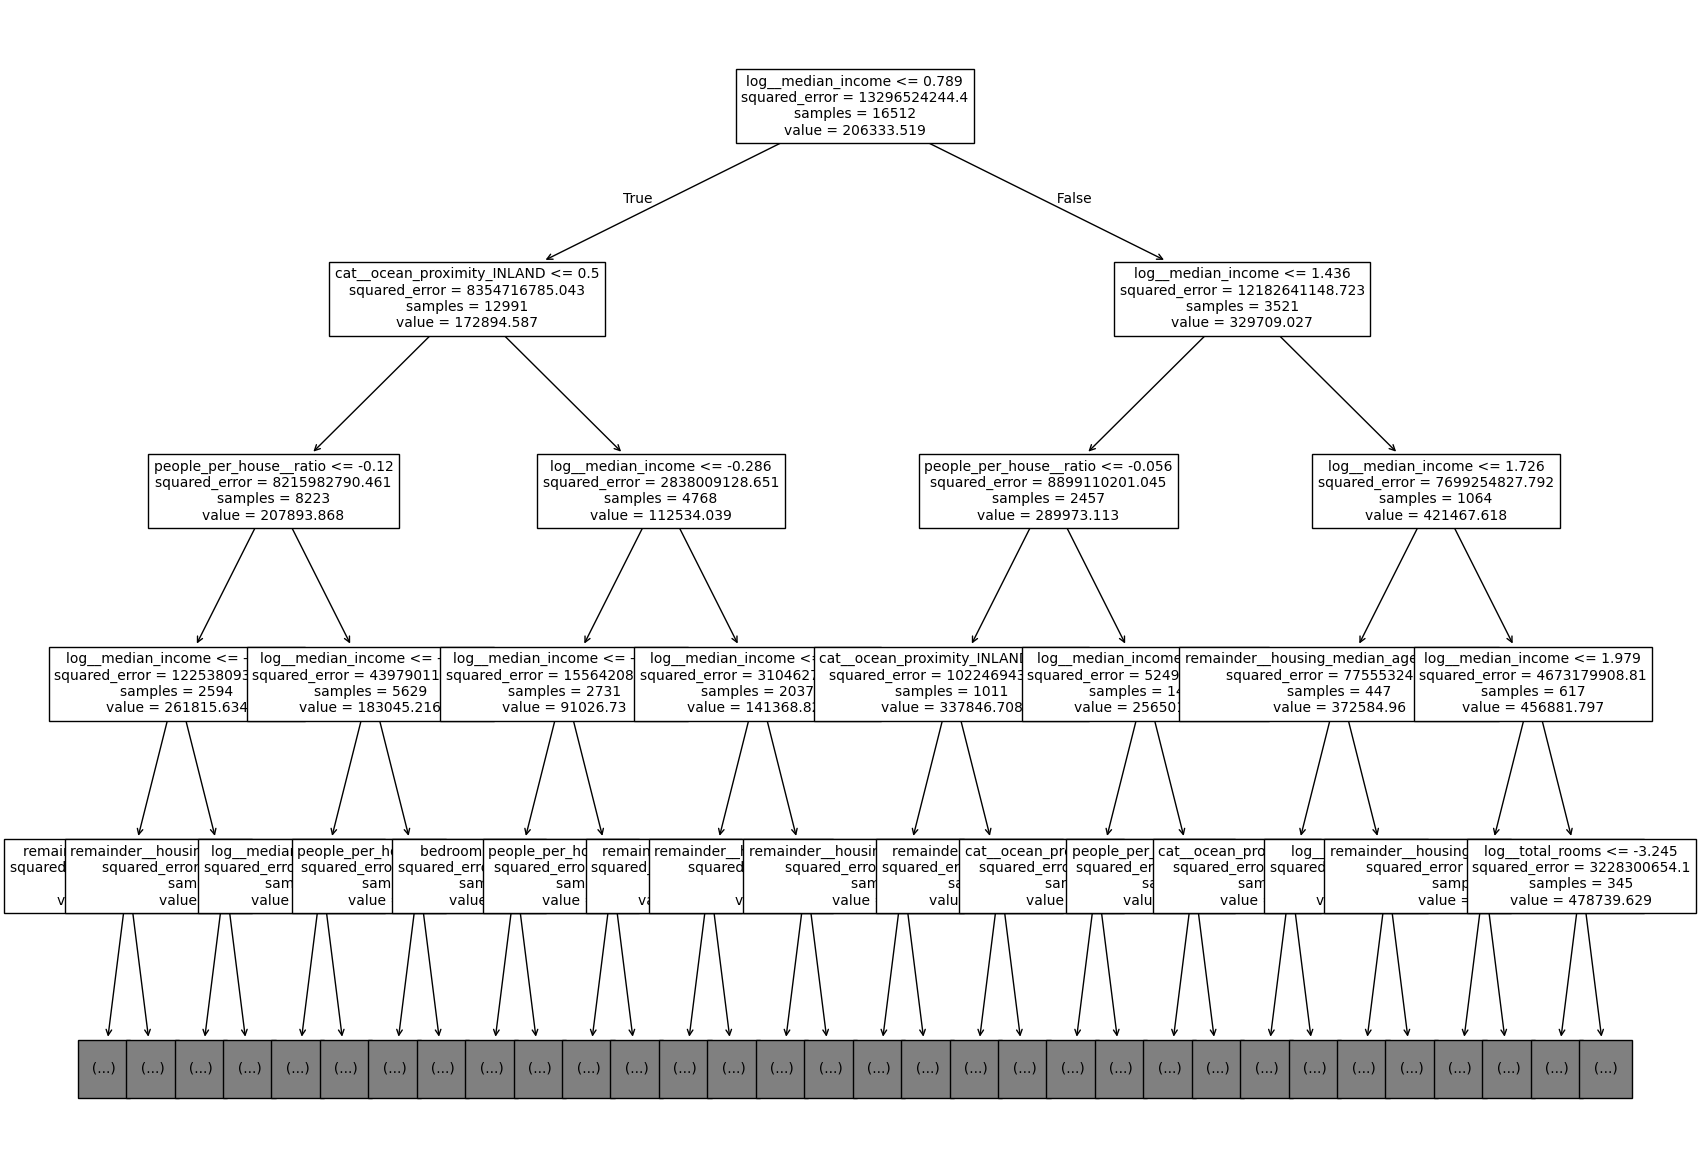

In [14]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree


preprocessing.fit(housing)   # Learn preprocessing parameters from the training set only
# Wrap the transformed data in a DataFrame (keeping column names); used later for pruning and cross-validation
housing_design = pd.DataFrame(preprocessing.transform(housing), columns = preprocessing.get_feature_names_out())


# min_samples_leaf=5: every leaf needs at least 5 samples, preventing an overly fine tree (basic regularization)
tree_reg = DecisionTreeRegressor(random_state=42, min_samples_leaf=5)
tree_reg.fit(housing_design, housing_labels);   # The trailing semicolon suppresses the output


fig, axes= plt.subplots(1, 1, figsize=(20, 15))   # Large canvas so the text in the tree is readable
# max_depth=4: only DRAW the top 4 levels (the model itself is unchanged); the full tree is too large to read
plot_tree(tree_reg, max_depth=4, feature_names=preprocessing.get_feature_names_out(),fontsize=10)
plt.show()

### Pruning a Decision Tree: Cost-Complexity Pruning

An unrestricted decision tree keeps splitting until every leaf is pure, thereby **memorizing the training data** (overfitting).  
**Pruning** balances goodness of fit against tree size. For a tree $T$, define:

$$ R_\alpha(T) = R(T) + \alpha \, |T| $$

- $R(T)$: total error of the tree on the training data (decreases as the tree grows)
- $|T|$: number of leaves (tree complexity)
- $\alpha \ge 0$: the **complexity penalty** (a hyperparameter) — the larger $\alpha$, the more pruning and the simpler the tree

**Procedure**

1. `cost_complexity_pruning_path()` computes a whole sequence of effective $\alpha$ values (`ccp_alphas`) and the corresponding total impurities (`impurities`);
2. Evaluate the CV RMSE for various $\alpha$ values;
3. Choose the $\alpha$ with the smallest CV RMSE.

In [15]:
# Compute the pruning path: the returned object contains ccp_alphas (candidate alphas) and impurities (total leaf impurity at each alpha)
tmp_path  = tree_reg.cost_complexity_pruning_path(housing_design, housing_labels)

ccp_alphas, impurities = tmp_path.ccp_alphas, tmp_path.impurities

**Code explanation**: There are typically **thousands** of candidate $\alpha$ values, and running cross-validation on all of them would be too slow. The loop below therefore takes every `tmp_step`-th value, i.e., **about 20 candidates**, and computes the 5-fold CV RMSE for each.

> Naming convention: variables starting with `tmp_` are temporary intermediate variables.  
> Also, `cross_val_score` follows a "**larger is better**" convention, so RMSE is returned as a **negative** value (`neg_root_mean_squared_error`); the code multiplies by `-1` to recover it.

In [16]:
from sklearn.model_selection import cross_val_score

tmp_cpp_len = len(ccp_alphas)                 # Total number of candidate alphas
tmp_step = int(np.floor(tmp_cpp_len/(20)))    # Step size: take about 20 evenly spaced candidates to save computation
tmp_ccp_alpha = ccp_alphas[0:tmp_cpp_len:tmp_step]
tmp_all_cv_rmse = []                          # Stores the 5-fold CV RMSE for each alpha
for i, tmp_alpha in enumerate(tmp_ccp_alpha):
    if i%5==0:
        print(i)                              # Print progress every 5 alphas
    tmp_tree_reg = DecisionTreeRegressor(random_state=42, ccp_alpha = tmp_alpha)
    # Multiply the negative RMSE by -1 to recover RMSE; np.mean averages over the 5 folds
    tmp_all_cv_rmse.append(-1*np.mean(cross_val_score(tmp_tree_reg, housing_design, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=5)))

0
5
10
15
20


In the plot below, the **x-axis is $\alpha$ and the y-axis is the CV RMSE**.  
The ideal $\alpha$ is at the **lowest point** of the curve: too small → the tree is too complex (overfitting); too large → too simple (underfitting).

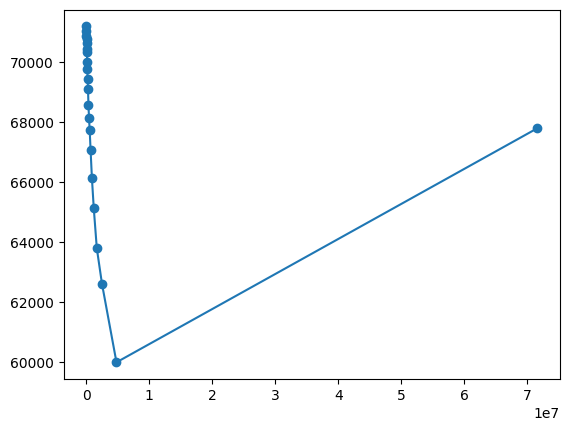

In [17]:
# Plot CV RMSE against alpha; 'o-' draws circles connected by a solid line
plt.plot(tmp_ccp_alpha,tmp_all_cv_rmse,'o-')

Find the position (index) of the smallest RMSE and extract the corresponding best $\alpha$.

> 💡 Since we only tried about 20 candidates, this is the best $\alpha$ *on our grid*. For finer tuning, narrow the search range and refine the grid (or use `GridSearchCV`).

In [18]:
# np.where finds the positions where RMSE equals the minimum; [0][0] takes the first matching index
np.where(tmp_all_cv_rmse==np.min(tmp_all_cv_rmse))[0][0]

np.int64(19)

In [19]:
# Use that index to get the best pruning coefficient alpha
tmp_cv_best_alpha = tmp_ccp_alpha[np.where(tmp_all_cv_rmse==np.min(tmp_all_cv_rmse))[0][0]]

### Retrain with the Best α and Inspect the Training Error

This time we chain **preprocessing and model into one pipeline**, `tree_reg_all = make_pipeline(preprocessing, tree_reg)`, so raw data can be passed in directly for prediction without manual transformation.

**Remember this number (training RMSE)**; we will compare it with the cross-validated RMSE shortly.

In [20]:
from sklearn.metrics import mean_squared_error

# Build the pruned decision tree using the alpha selected by cross-validation
tree_reg = DecisionTreeRegressor(random_state=42, ccp_alpha=tmp_cv_best_alpha)

# Full pipeline: raw data -> preprocessing -> decision tree
tree_reg_all = make_pipeline(preprocessing, tree_reg)
tree_reg_all.fit(housing, housing_labels);


housing_predictions = tree_reg_all.predict(housing)   # Predict on the TRAINING set
# Training RMSE: compute MSE, then take the square root (newer sklearn versions also offer root_mean_squared_error)
tree_rmse = np.sqrt(mean_squared_error(housing_labels, housing_predictions))
tree_rmse

np.float64(51722.617532923476)

### Visualization: Actual vs. Predicted Values

The x-axis is the **actual house value**, the y-axis the **predicted house value**, and the red dashed line is $y = x$ (perfect prediction). **The closer the points are to the red line, the more accurate the predictions.**

Things to notice:

- A decision tree predicts **one constant per leaf**, so the plot shows **horizontal bands** (many different actual values receive the same prediction).
- The vertical column of points at the right side arises because house values in this dataset are **capped** at about \$500,000 — a property of the data, not a model error.

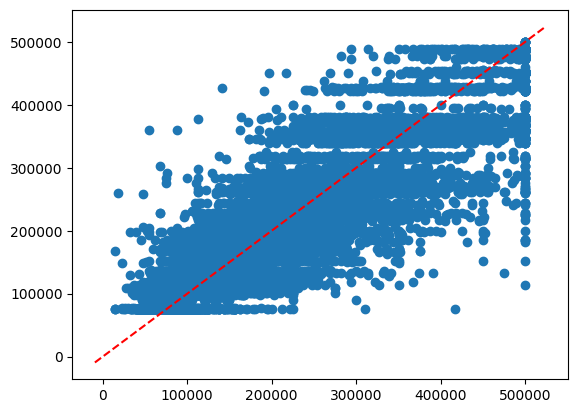

In [21]:
# Draw a red dashed line y = intercept + slope * x on the current plot
def abline(slope, intercept):
    axes = plt.gca()                          # Get the current axes
    x_vals = np.array(axes.get_xlim())        # The two endpoints of the x-axis range
    y_vals = intercept + slope * x_vals
    plt.plot(x_vals, y_vals, 'r--')


plt.plot(housing_labels,housing_predictions,'o')   # Scatter plot: x = actual, y = predicted
abline(1,0)                                         # Reference line y = x (slope 1, intercept 0)

### Estimate Real Performance with 10-Fold Cross-Validation

We cross-validate the **entire pipeline** (`cv=10`). Because preprocessing is inside the pipeline, **in each fold the preprocessing is re-fit using only that fold's training part**, so no data leakage occurs.

> Comparison: the gap between "training RMSE" and "CV RMSE" indicates the degree of overfitting.

In [22]:
# 10-fold cross-validation; the minus sign turns neg_RMSE back into RMSE, giving 10 values (one per fold)
tree_rmses_cv = -cross_val_score(tree_reg_all, housing, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=10)

In [23]:
np.mean(tree_rmses_cv)   # Mean of the 10 fold RMSEs: the estimated generalization error of the pruned tree

np.float64(59172.016481576095)

## 7.2 Random Forest

**Core idea**

1. Draw many different samples from the training data using the **bootstrap** (sampling with replacement);
2. Train one decision tree per sample (you can additionally use `max_features` to **consider only a random subset of features at each split**; `RandomForestRegressor` considers all features by default, so its randomness comes mainly from the bootstrap, whereas `RandomForestClassifier` defaults to $\sqrt{p}$ features);
3. At prediction time, **average** the predictions of all trees.

**Why does it work?** A single tree has high variance; averaging many less-correlated trees substantially reduces variance while barely changing bias.  
`RandomForestRegressor` defaults to `n_estimators=100` (100 trees).

> 🔍 **Observe**: the random forest's training RMSE is far below its CV RMSE, meaning it nearly memorizes the training data (overfitting); yet its CV RMSE is still better than that of a single decision tree.

In [24]:
from sklearn.ensemble import RandomForestRegressor

# Pipeline: preprocessing -> random forest
forest_reg = make_pipeline(preprocessing,
                           RandomForestRegressor(random_state=42))


forest_reg.fit(housing, housing_labels)
housing_predictions = forest_reg.predict(housing)   # Predict on the TRAINING set
forest_rmse = np.sqrt(mean_squared_error(housing_labels, housing_predictions))   # Training RMSE
forest_rmse

np.float64(18469.486046590784)

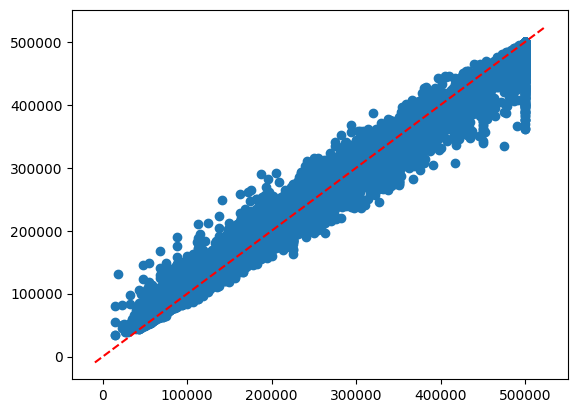

In [25]:
plt.plot(housing_labels,housing_predictions,'o')   # Actual vs. predicted (training set)
abline(1,0)                                         # Reference line y = x

In [26]:
# 10-fold CV RMSE (a more reliable estimate of generalization error). Training many trees takes a while
forest_cv_rmses = -cross_val_score(forest_reg, housing, housing_labels,
                                scoring="neg_root_mean_squared_error", cv=10)
np.mean(forest_cv_rmses)

np.float64(49632.089212073726)

## 7.3 Gradient Boosting

**Core idea** (additive model):

$$ F_m(x) = F_{m-1}(x) + \nu \cdot h_m(x) $$

1. Start from a simple prediction $F_0$ (e.g., the mean);
2. In each round, train a **shallow tree** $h_m$ to fit the current model's **residuals** (more precisely, the negative gradient of the loss);
3. Multiply that tree by the **learning rate** $\nu$ (default 0.1) and add it to the model;
4. Repeat `n_estimators` times (500 here).

**Differences from random forest**

| | Random forest | Gradient boosting |
|---|---|---|
| How trees are trained | In parallel, independently | **Sequentially**; each tree corrects the previous ones |
| Depth of each tree | Usually deep | Usually shallow (default `max_depth=3`) |
| Mainly reduces | Variance | Bias |
| Tuning difficulty | Lower | Higher (`n_estimators`, learning rate, depth must be tuned together) |

In [27]:
from sklearn.ensemble import GradientBoostingRegressor

# n_estimators=500: build 500 trees in total (other hyperparameters at defaults: learning_rate=0.1, max_depth=3)
boost_reg = make_pipeline(preprocessing,
                           GradientBoostingRegressor(random_state=42, n_estimators=500))


boost_reg.fit(housing, housing_labels)
housing_predictions = boost_reg.predict(housing)   # Predict on the TRAINING set
boost_rmse = np.sqrt(mean_squared_error(housing_labels, housing_predictions))   # Training RMSE
boost_rmse

np.float64(40750.546923712864)

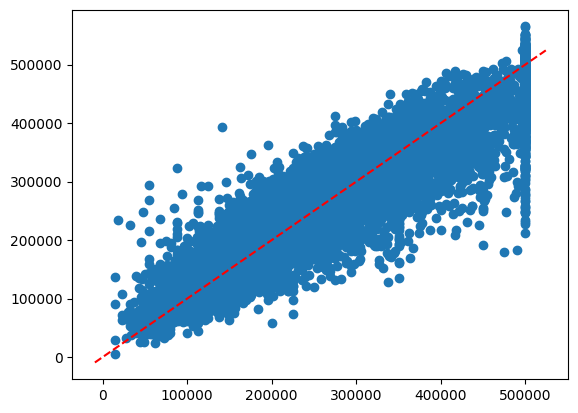

In [28]:
plt.plot(housing_labels,housing_predictions,'o')   # Actual vs. predicted (training set)
abline(1,0)                                         # Reference line y = x

In [29]:
# 10-fold CV RMSE (takes some time because 500 trees are trained in every fold)
boost_cv_rmses = -cross_val_score(boost_reg, housing, housing_labels,
                                scoring="neg_root_mean_squared_error", cv=10)
np.mean(boost_cv_rmses)

np.float64(47334.14559462941)

## 7.4 Comparing the Regression Models

The table puts the **10-fold CV RMSE** of the three methods side by side (**smaller is better**).

> ⚠️ The column name `rmse_csv` in the original code is a typo for `rmse_cv` (cross-validation). We keep it unchanged so that the stored output matches the code.

**Questions to consider when reading the table**

1. Which method has the smallest generalization error? By how many dollars does it improve on a single decision tree?
2. What is the gap between training RMSE and CV RMSE for each model, and what does it mean?
3. Which hyperparameters could be tuned to improve further? (Hint: `n_estimators`, `learning_rate`, `max_depth`, `max_features`, …)

In [30]:
all_methods = ["Tree","Random Forest","Boosting"]
all_rmse_cv = [np.mean(tree_rmses_cv), np.mean(forest_cv_rmses), np.mean(boost_cv_rmses)]
pd.DataFrame({"method": all_methods,"rmse_csv": all_rmse_cv})   # Collect into a table for comparison

,method,rmse_csv
0,Tree,59172.016482
1,Random Forest,49632.089212
2,Boosting,47334.145595


---
# 8. MNIST Handwritten Digit Recognition (Classification)

So far we have done **regression** (predicting a continuous value). This section turns to **classification** (predicting a discrete class) using the same three tree-based models, so you can compare how evaluation differs between the two tasks.

### About the MNIST dataset

- **70,000** grayscale images of handwritten digits (0–9, i.e., **10 classes**).
- Each image is $28 \times 28 = 784$ pixels, with values from 0 (white) to 255 (black).
- **Flattening** each image into a vector of length 784 gives 784 features.
- Conventional split: **the first 60,000 images for training, the last 10,000 for testing**.

### Evaluation metric: Accuracy

$$ \text{Accuracy} = \frac{\text{number of correct predictions}}{\text{total number of samples}} $$

**Larger is better** (the opposite of RMSE in regression).

## 8.1 Load the Data

`fetch_openml` downloads the data from the OpenML website; `as_frame=False` returns **NumPy arrays** (instead of a pandas DataFrame). An internet connection is required the first time.

In [31]:
from sklearn.datasets import fetch_openml
import numpy as np

mnist = fetch_openml('mnist_784', as_frame=False)   # Download MNIST (dataset name mnist_784: 784 pixel features)

In [32]:
# extra code – it's a bit too long (the dataset description)
print(mnist.DESCR)

**Author**: Yann LeCun, Corinna Cortes, Christopher J.C. Burges  
**Source**: [MNIST Website](http://yann.lecun.com/exdb/mnist/) - Date unknown  
**Please cite**:  

The MNIST database of handwritten digits with 784 features, raw data available at: http://yann.lecun.com/exdb/mnist/. It can be split in a training set of the first 60,000 examples, and a test set of 10,000 examples  

It is a subset of a larger set available from NIST. The digits have been size-normalized and centered in a fixed-size image. It is a good database for people who want to try learning techniques and pattern recognition methods on real-world data while spending minimal efforts on preprocessing and formatting. The original black and white (bilevel) images from NIST were size normalized to fit in a 20x20 pixel box while preserving their aspect ratio. The resulting images contain grey levels as a result of the anti-aliasing technique used by the normalization algorithm. the images were centered in a 28x28 image b

In [33]:
mnist.keys()  # extra code – we only use data and target in this notebook

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

### Inspect the Data Shapes

- `X`: the feature matrix of shape `(70000, 784)`; each row is a flattened image
- `y`: the labels (0–9) of shape `(70000,)`

> 📌 Note: the entries of `y` are **strings** (`'5'`, `'0'`, …), not integers. This is fine for classifiers, which treat each string as a class.

In [34]:
X, y = mnist.data, mnist.target   # X: pixel features; y: labels (digits 0–9, stored as strings)
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [35]:
X.shape   # (number of samples, number of features) = (70000, 784)

(70000, 784)

In [36]:
y         # Label array

array(['5', '0', '4', ..., '4', '5', '6'], dtype=object)

In [37]:
y.shape   # (70000,)

(70000,)

In [38]:
28 * 28   # Check: each image has 28×28 = 784 pixels

784

## 8.2 Visualizing the Data

`plot_digit()` reshapes a length-784 vector back into a $28 \times 28$ matrix and displays it with `imshow`.  
`cmap="binary"` uses a black-and-white color map (larger value = darker), and `axis("off")` hides the axes.

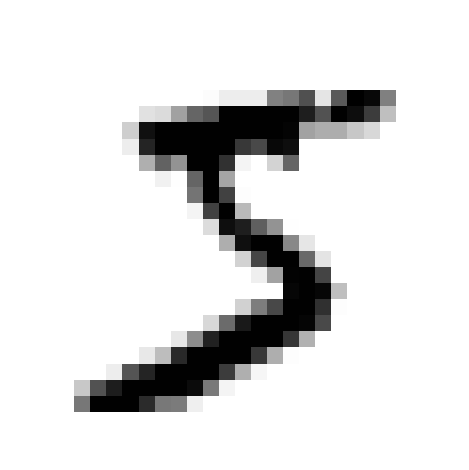

In [39]:
import matplotlib.pyplot as plt

def plot_digit(image_data):
    image = image_data.reshape(28, 28)       # Restore the length-784 vector to a 28×28 image
    plt.imshow(image, cmap="binary")         # Display in black and white
    plt.axis("off")                          # Hide the axes

some_digit = X[0]                            # Take the first image
plot_digit(some_digit)
save_fig("some_digit_plot")  # extra code – calls the function defined in Section 2.2 to save the figure
plt.show()

In [40]:
y[0]   # True label of the first image (should match the plot above)

'5'

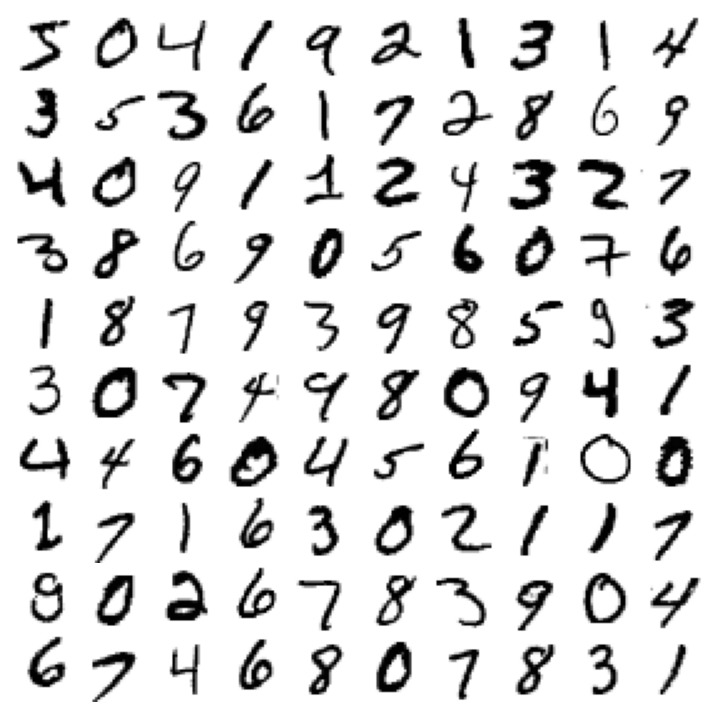

In [41]:
# extra code – this cell generates and saves Figure 3–2: the first 100 digits
plt.figure(figsize=(9, 9))
for idx, image_data in enumerate(X[:100]):
    plt.subplot(10, 10, idx + 1)             # 10×10 grid of subplots; this is cell idx+1
    plot_digit(image_data)
plt.subplots_adjust(wspace=0, hspace=0)      # No gaps between subplots
save_fig("more_digits_plot", tight_layout=False)
plt.show()

## 8.3 Splitting into Training and Test Sets

MNIST is **pre-arranged**: the first 60,000 samples are for training and the last 10,000 for testing, so we simply slice by index (no random split needed).

> 💡 The commented-out second line is a **faster teaching version** using only the first 5,000 training samples. Gradient boosting on 10 classes (later) is very slow, so you may prefer it for in-class demos.  
> 📌 As in the regression part, **`X_test` and `y_test` are not used in this notebook**; all evaluation below is done on the training set (including cross-validation).

In [42]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]
#X_train, X_test, y_train, y_test = X[:5000], X[60000:], y[:5000], y[60000:]   # Smaller version (for speed)

## 8.4 Decision Tree Classifier

We first train a completely **unrestricted** decision tree and predict on the **training set**.

**How to read a confusion matrix**  
Rows = true class, columns = predicted class. The **diagonal** counts correct predictions; off-diagonal cells are errors (e.g., a 4 misclassified as a 9).

> ⚠️ A confusion matrix on the **training set** will show an almost perfect diagonal, because an unpruned tree memorizes the training data. This **does not reflect real performance**; it is only meaningful together with cross-validation.

In [43]:
from sklearn.tree import DecisionTreeClassifier

# A decision tree with no restrictions (grows until every leaf is pure)
Tree_class = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
y_train_pred = Tree_class.predict(X_train)   # Predict on the training set

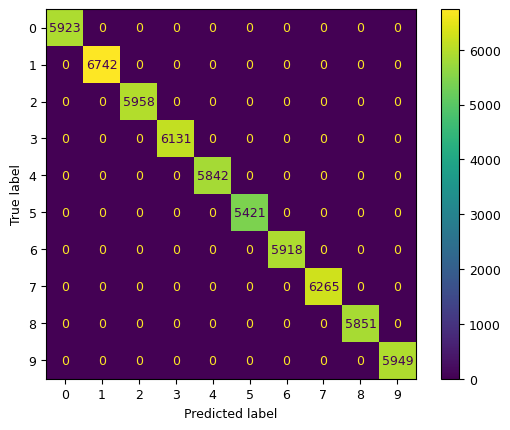

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.rc('font', size=9)  # extra code – make the text smaller
# Draw the confusion matrix: from_predictions uses the true and predicted labels directly
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)
plt.show()

In [45]:
np.mean(y_train==y_train_pred)   # Training accuracy: the mean of a boolean array = share of correct predictions

np.float64(1.0)

**The training accuracy is 100%**, a textbook case of overfitting. Next we use **3-fold cross-validation** for a more reliable accuracy estimate:

In [46]:
# 3-fold CV accuracy (one tree is trained per fold; returns 3 accuracies)
tmp_cv_score = cross_val_score(Tree_class, X_train, y_train, cv=3, scoring="accuracy")
tmp_cv_score

array([0.85835, 0.8597 , 0.862  ])

In [47]:
tmp_tree_cv_score_mean = np.mean(tmp_cv_score)   # Average and store for the final comparison table

### Pruning the Classification Tree

The procedure is identical to the regression tree in Section 7.1:

1. Compute the pruning path → 2. take about 20 candidate $\alpha$ values → 3. choose the $\alpha$ with the **highest** CV accuracy.

**Difference from regression**: here we **maximize accuracy** (`np.max`) rather than minimize RMSE.

In [48]:
# Pruning path of the classification tree
tmp_path  = Tree_class.cost_complexity_pruning_path(X_train, y_train)

ccp_alphas, impurities = tmp_path.ccp_alphas, tmp_path.impurities

In [49]:
tmp_cpp_len = len(ccp_alphas)
tmp_step = int(np.floor(tmp_cpp_len/(20)))     # About 20 candidate alphas
tmp_ccp_alpha = ccp_alphas[0:tmp_cpp_len:tmp_step]
tmp_all_cv_acc = []                            # Stores the 3-fold CV accuracy for each alpha
for i, tmp_alpha in enumerate(tmp_ccp_alpha):
    if i%5==0:
        print(i)                               # Show progress
    # The variable name tmp_tree_reg is reused from earlier, but this is actually a CLASSIFICATION tree
    tmp_tree_reg = DecisionTreeClassifier(random_state=0, ccp_alpha = tmp_alpha)
    tmp_all_cv_acc.append(np.mean(cross_val_score(tmp_tree_reg, X_train, y_train, cv=3, scoring="accuracy")))

0
5
10
15
20


The plot below shows CV accuracy against $\alpha$; we look for the **highest point** of the curve.

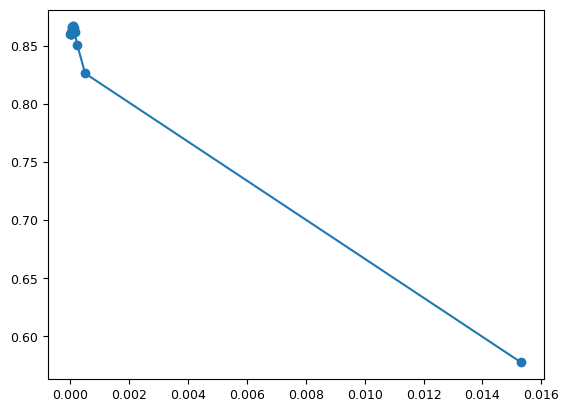

In [50]:
plt.plot(tmp_ccp_alpha,tmp_all_cv_acc,'o-')   # x-axis: alpha; y-axis: CV accuracy

In [51]:
# Find the position (index) of the highest accuracy
np.where(tmp_all_cv_acc==np.max(tmp_all_cv_acc))[0][0]

np.int64(14)

In [52]:
# Take the best alpha and retrain the pruned decision tree with it
tmp_alpha = tmp_ccp_alpha[np.where(tmp_all_cv_acc==np.max(tmp_all_cv_acc))[0][0]]
Tree_class2 = DecisionTreeClassifier(random_state=0, ccp_alpha = tmp_alpha).fit(X_train, y_train)
y_train_pred = Tree_class2.predict(X_train)

### Visualizing the Pruned Classification Tree

Because the inputs are 784 pixels, the conditions read like `x[378] <= some value`, meaning "is the gray value of **pixel 378** ≤ some value?".  
In each node, `class` is the majority class, and `gini` is the Gini impurity (closer to 0 = purer node).

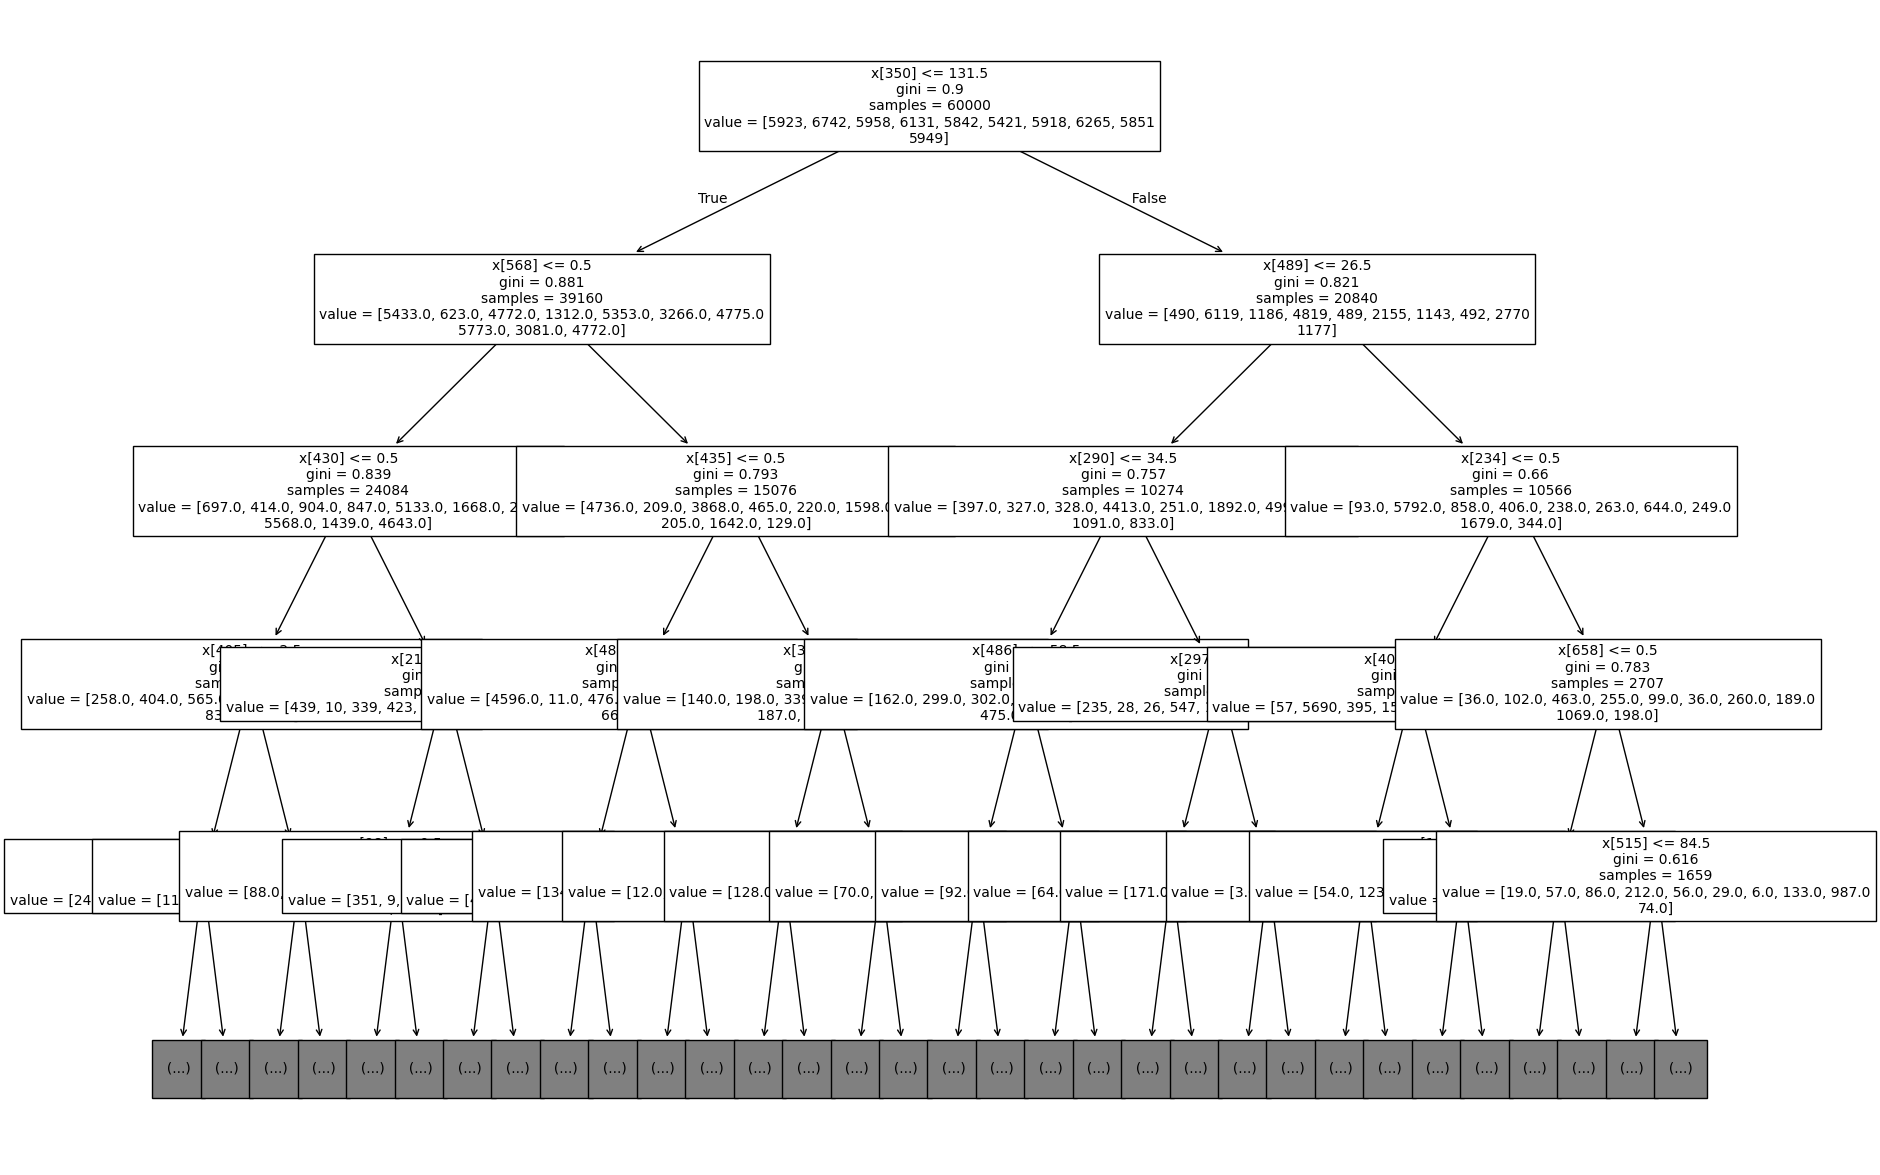

In [53]:
from sklearn.tree import plot_tree

fig, axes= plt.subplots(1, 1, figsize=(20, 15))
plot_tree(Tree_class2, max_depth=4,fontsize=10)   # Draw only the top 4 levels; features are unnamed, so shown as x[pixel index]
plt.show()

In [54]:
np.max(tmp_all_cv_acc)   # Best CV accuracy after pruning

np.float64(0.8666833333333334)

In [55]:
tmp_tree_adjust_cv_score_mean = np.max(tmp_all_cv_acc)   # Store for the final comparison

## 8.5 Random Forest Classifier

The principle is the same as in Section 7.2, except that:

- For classification, all trees **vote** (or average class probabilities) to determine the final class;
- It provides **feature importances**, telling us which pixels help most in recognizing digits.

`verbose=1` shows progress during training (printed to `stderr`, hence the `[Parallel(n_jobs=1)]...` messages).

In [56]:
from sklearn.ensemble import RandomForestClassifier

# n_estimators=100: 100 trees; verbose=1: show training progress
RFC_class = RandomForestClassifier(random_state=0, n_estimators = 100, verbose = 1).fit(X_train, y_train)
y_train_pred = RFC_class.predict(X_train)   # Predict on the training set

[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:   30.1s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:  1.0min finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    1.1s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    2.3s finished


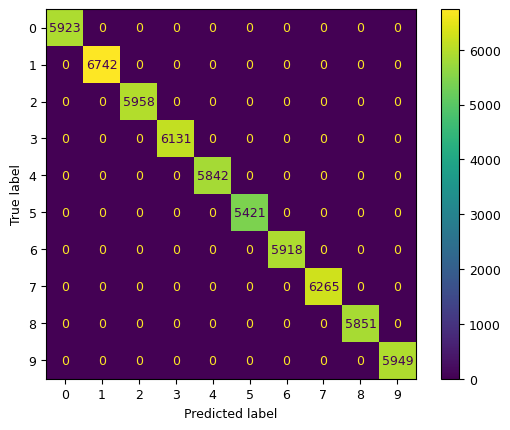

In [57]:
plt.rc('font', size=9)  # extra code – make the text smaller
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)   # Confusion matrix on the training set
plt.show()

In [58]:
np.mean(y_train==y_train_pred)   # Training accuracy (again very high, since the model has seen this data)

np.float64(1.0)

In [59]:
# 3-fold CV accuracy: this is the more reliable performance estimate
tmp_cv_score = cross_val_score(RFC_class, X_train, y_train, cv=3, scoring="accuracy")
tmp_cv_score

[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:   17.8s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:   37.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.4s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.8s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:   17.7s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:   36.8s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.5s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.9s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:   17.5s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:   36.0s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.6s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    1.1s finished


array([0.96465, 0.96225, 0.9659 ])

In [60]:
tmp_RF_cv_score_mean = np.mean(tmp_cv_score)   # Average and store for the final comparison

### Feature Importance

A random forest's `feature_importances_` measures **how much each feature (pixel) reduces impurity on average**; the importances sum to 1.

- The first cell below lists the **most important pixels** (format: `(importance, pixel index)`, sorted in descending order).
- The second reshapes the 784 importances into a 28×28 image and draws it with `plot_digit` — **darker pixels are more important**.

**Observation**: the important pixels cluster in the **center** of the image (where strokes usually pass); border pixels are almost always blank and thus have importance near 0.

In [61]:
feature_importances = RFC_class.feature_importances_   # Importance of each pixel (784 values summing to 1)
feature_importances.round(2)                            # (Not the last line, so not displayed; just demonstrates rounding)

# Pair (importance, pixel index) and sort in descending order; the first entries are the most important pixels
sorted(zip(feature_importances,
           np.arange((X_train.shape[1]))),
           reverse=True)

[(np.float64(0.010437113662093416), np.int64(378)),
 (np.float64(0.010059999504401234), np.int64(433)),
 (np.float64(0.008391255109723644), np.int64(350)),
 (np.float64(0.008114961476686553), np.int64(405)),
 (np.float64(0.008096867069272894), np.int64(569)),
 (np.float64(0.00796217674144147), np.int64(409)),
 (np.float64(0.007483223833112436), np.int64(461)),
 (np.float64(0.007477148690748894), np.int64(406)),
 (np.float64(0.00744829598088821), np.int64(318)),
 (np.float64(0.007024624455806562), np.int64(542)),
 (np.float64(0.006809744119143895), np.int64(429)),
 (np.float64(0.0065288929641846224), np.int64(489)),
 (np.float64(0.006454393650641983), np.int64(210)),
 (np.float64(0.006329444343023769), np.int64(377)),
 (np.float64(0.0062733592378042225), np.int64(291)),
 (np.float64(0.006257859270298404), np.int64(155)),
 (np.float64(0.006201144796049563), np.int64(375)),
 (np.float64(0.006130207177579708), np.int64(347)),
 (np.float64(0.006101888441893037), np.int64(437)),
 (np.float64

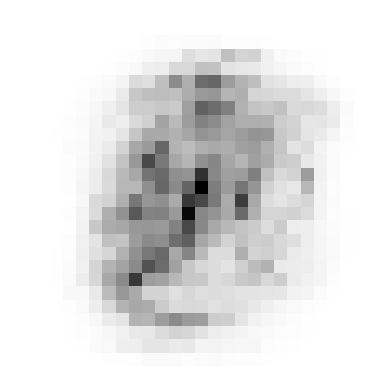

In [62]:
plot_digit(feature_importances)   # Draw importances as a 28×28 "heat map": darker = more important

## 8.6 Gradient Boosting Classifier

The principle is the same as in Section 7.3. For classification, note that:

- With **K classes**, each round must **build K trees at once** (one per class). MNIST has 10 classes, so `n_estimators=250` actually trains **250 × 10 = 2,500 trees**.
- With 784 features and 60,000 samples, **training is very slow** (the "Remaining Time" estimate in the output is long). In class, use the smaller data version from Section 8.3 or reduce `n_estimators`.

`max_depth=3`: each tree has at most 3 levels (shallow trees are standard in boosting).

In [63]:
from sklearn.ensemble import GradientBoostingClassifier

# n_estimators=250 rounds, each tree at most 3 levels deep; verbose=1: show training loss and estimated remaining time each round
boost_class = GradientBoostingClassifier(n_estimators=250, max_depth=3, random_state=0, verbose = 1).fit(X_train, y_train)
y_train_pred = boost_class.predict(X_train)

      Iter       Train Loss   Remaining Time 
         1           1.9103          118.07m
         2           1.6843          116.88m
         3           1.5170          115.64m
         4           1.3837          114.71m
         5           1.2679          114.31m
         6           1.1712          113.97m
         7           1.0834          113.42m
         8           1.0090          113.01m
         9           0.9433          112.45m
        10           0.8849          112.43m
        20           0.5524          108.23m
        30           0.4018          102.60m
        40           0.3203           97.63m
        50           0.2676           92.72m
        60           0.2320           87.79m
        70           0.2058           82.95m
        80           0.1848           78.16m
        90           0.1681           73.40m
       100           0.1601           68.69m
       200           0.0810           22.71m


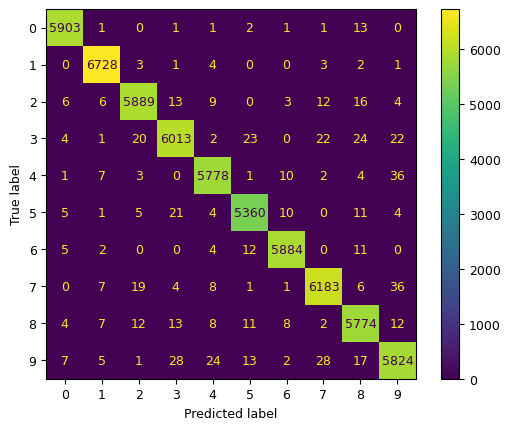

In [64]:
plt.rc('font', size=9)  # extra code – make the text smaller
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)   # Confusion matrix on the training set
plt.show()

In [65]:
np.mean(y_train==y_train_pred)   # Training accuracy

np.float64(0.9889333333333333)

In [66]:
# 3-fold CV accuracy (the model is retrained 3 times, so this is very slow)
tmp_cv_score = cross_val_score(boost_class, X_train, y_train, cv=3, scoring="accuracy")
tmp_cv_score

      Iter       Train Loss   Remaining Time 
         1           1.9085          109.52m
         2           1.6816          109.34m
         3           1.5133          109.12m
         4           1.3798          109.00m
         5           1.2642          108.55m
         6           1.1660          108.13m
         7           1.0804          107.79m
         8           1.0067          107.30m
         9           0.9415          106.82m
        10           0.8831          106.34m
        20           0.5467          101.53m
        30           0.3985           96.96m
        40           0.3136           92.47m
        50           0.2622           88.01m
        60           0.2263           83.56m
        70           0.1990           79.13m
        80           0.1782           74.66m
        90           0.1619           70.24m
       100           0.1484           65.82m
       200           0.0707           21.91m
      Iter       Train Loss   Remaining Time 
        

array([0.9578, 0.9571, 0.9602])

In [67]:
tmp_GB_cv_score_mean = np.mean(tmp_cv_score)   # Average and store for the final comparison

## 8.7 Comparing the Classification Models

We put the **3-fold CV accuracy** of all four models together (**higher is better**).

> 📌 The variable name `all_rmse_cv` is carried over from the regression part; here it actually stores **accuracy**, not RMSE.

**Questions to consider when reading the table**

1. By how much does pruning improve a single tree's accuracy? Why is the improvement limited?
2. Why does combining many trees (random forest, boosting) improve accuracy so much?
3. How does the gap between training accuracy and CV accuracy for gradient boosting compare with that of the random forest?

In [68]:
import pandas as pd

In [69]:
all_methods = ["Tree","Tree with Adjust","Random Forest","Boosting"]
all_rmse_cv = [tmp_tree_cv_score_mean,          # Single unpruned decision tree
               tmp_tree_adjust_cv_score_mean,   # Single pruned decision tree
               tmp_RF_cv_score_mean,            # Random forest
               tmp_GB_cv_score_mean]            # Gradient boosting
pd.DataFrame({"method": all_methods,"CV Accuracy": all_rmse_cv})   # Collect into a comparison table

,method,CV Accuracy
0,Tree,0.860017
1,Tree with Adjust,0.866683
2,Random Forest,0.964267
3,Boosting,0.958367


---
# 9. Summary and Discussion Questions

## Key Takeaways

1. **Split first, then do anything else**: hold out the test set at the start and use it only at the end; stratified sampling makes it more representative.
2. **Manage preprocessing with `Pipeline` + `ColumnTransformer`**: fit on training data only and apply the same transformation to other data. This prevents data leakage and makes the workflow reproducible and deployable.
3. **Training error ≠ real performance**: flexible models (unpruned trees, random forests, boosting) can achieve very small training error; use **cross-validation** to estimate generalization.
4. **A single decision tree is interpretable but unstable**; **ensemble methods** (random forest / gradient boosting) usually improve prediction markedly, at the cost of **reduced interpretability** and **more computation**.
5. **Regression uses RMSE (smaller is better); classification uses accuracy (larger is better)**. In practice, complement them with other metrics as appropriate (MAE, $R^2$, precision/recall, F1, AUC, …).

